# Verifikasi Hasil Eksperimen Tugas 05
**Andrew Wijaya | NIM 2802508363**

Notebook ini benar-benar dieksekusi pada pemeriksaan lokal. Ia menghitung ulang metrik dan menampilkan artefak training Colab yang sudah tersimpan. **Notebook ini tidak menjalankan ulang training dan tidak menggantikan notebook Colab beroutput.**


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, confusion_matrix
from IPython.display import display, Image

ROOT = Path.cwd()
RAW = ROOT / "raw_logs"
assert RAW.is_dir(), "Jalankan notebook dari folder paket hasil ekstraksi ZIP."
summary = pd.read_csv(RAW / "experiment_summary.csv")
protocol = json.loads((RAW / "protocol.json").read_text())
environment = json.loads((RAW / "environment.json").read_text())
print("Environment training asli:", environment)
display(summary[["name", "trainable_parameters", "best_epoch", "epochs_run",
                 "training_seconds", "validation_accuracy", "test_macro_f1"]])


Environment training asli: {'python': '3.13.16', 'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'device': 'cpu', 'gpu': None}


,name,trainable_parameters,best_epoch,epochs_run,training_seconds,validation_accuracy,test_macro_f1
0,B1,11181642,4,9,3794.933527,0.404040,0.354973
1,B2,5130,13,18,3003.078963,0.929293,0.913205
2,B3,8398858,7,12,2659.513075,0.962963,0.936307
3,B4_no_aug,8398858,4,9,1965.727282,0.949495,0.933086


In [2]:
manifest = pd.read_csv(RAW / "split_manifest.csv")
assert manifest.path.is_unique
assert manifest.split.value_counts().to_dict() == {"train": 1386, "test": 298, "validation": 297}
for split in ["train", "validation", "test"]:
    assert set(manifest.loc[manifest.split == split, "label"]) == set(range(10))
display(pd.crosstab(manifest.breed, manifest.split))
print("PASS: 1.981 path unik, split 70/15/15, semua split memiliki sepuluh kelas.")


PASS: 1.981 path unik, split 70/15/15, semua split memiliki sepuluh kelas.


split,test,train,validation
breed,,,
Abyssinian,30,138,30
Bengal,30,140,30
Birman,30,140,30
Bombay,28,129,27
British_Shorthair,30,140,30
american_bulldog,30,140,30
american_pit_bull_terrier,30,140,30
basset_hound,30,140,30
beagle,30,140,30


In [3]:
verified = []
for row in summary.itertuples(index=False):
    folder = RAW / row.name
    predictions = pd.read_csv(folder / "test_predictions.csv")
    history = pd.read_csv(folder / "history.csv")
    assert len(predictions) == 298
    assert len(history) == row.epochs_run
    assert predictions.path.tolist() == manifest.loc[manifest.split == "test", "path"].tolist() or set(predictions.path) == set(manifest.loc[manifest.split == "test", "path"])
    accuracy = (predictions.label == predictions.predicted_label).mean()
    macro_f1 = f1_score(predictions.label, predictions.predicted_label,
                        labels=list(range(10)), average="macro", zero_division=0)
    best = history.loc[history.val_loss.idxmin()]
    assert np.isclose(accuracy, row.test_accuracy)
    assert np.isclose(macro_f1, row.test_macro_f1)
    assert best.epoch == row.best_epoch
    assert np.isclose(best.val_loss, row.validation_loss)
    assert np.isclose(best.val_accuracy, row.validation_accuracy)
    verified.append({"experiment": row.name, "test_correct": int(accuracy * len(predictions) + 0.5),
                     "test_accuracy": accuracy, "macro_f1_recomputed": macro_f1,
                     "best_epoch": int(best.epoch)})
display(pd.DataFrame(verified))
print("PASS: accuracy, Macro F1, jumlah epoch dan checkpoint terbaik cocok dengan log.")


PASS: accuracy, Macro F1, jumlah epoch dan checkpoint terbaik cocok dengan log.


,experiment,test_correct,test_accuracy,macro_f1_recomputed,best_epoch
0,B1,114,0.382550,0.354973,4
1,B2,272,0.912752,0.913205,13
2,B3,279,0.936242,0.936307,7
3,B4_no_aug,278,0.932886,0.933086,4


Model terpilih melalui validation loss: B4_no_aug


,Abyssinian,Bengal,Birman,Bombay,British_Shorthair,american_bulldog,american_pit_bull_terrier,basset_hound,beagle,boxer
Abyssinian,26,4,0,0,0,0,0,0,0,0
Bengal,0,30,0,0,0,0,0,0,0,0
Birman,0,0,30,0,0,0,0,0,0,0
Bombay,0,0,0,28,0,0,0,0,0,0
British_Shorthair,0,0,0,1,29,0,0,0,0,0
american_bulldog,0,0,0,0,0,26,0,0,2,2
american_pit_bull_terrier,0,0,0,0,0,3,26,0,0,1
basset_hound,0,0,0,0,0,0,0,29,1,0
beagle,0,0,0,0,0,0,1,2,27,0
boxer,0,0,0,0,0,1,1,0,1,27


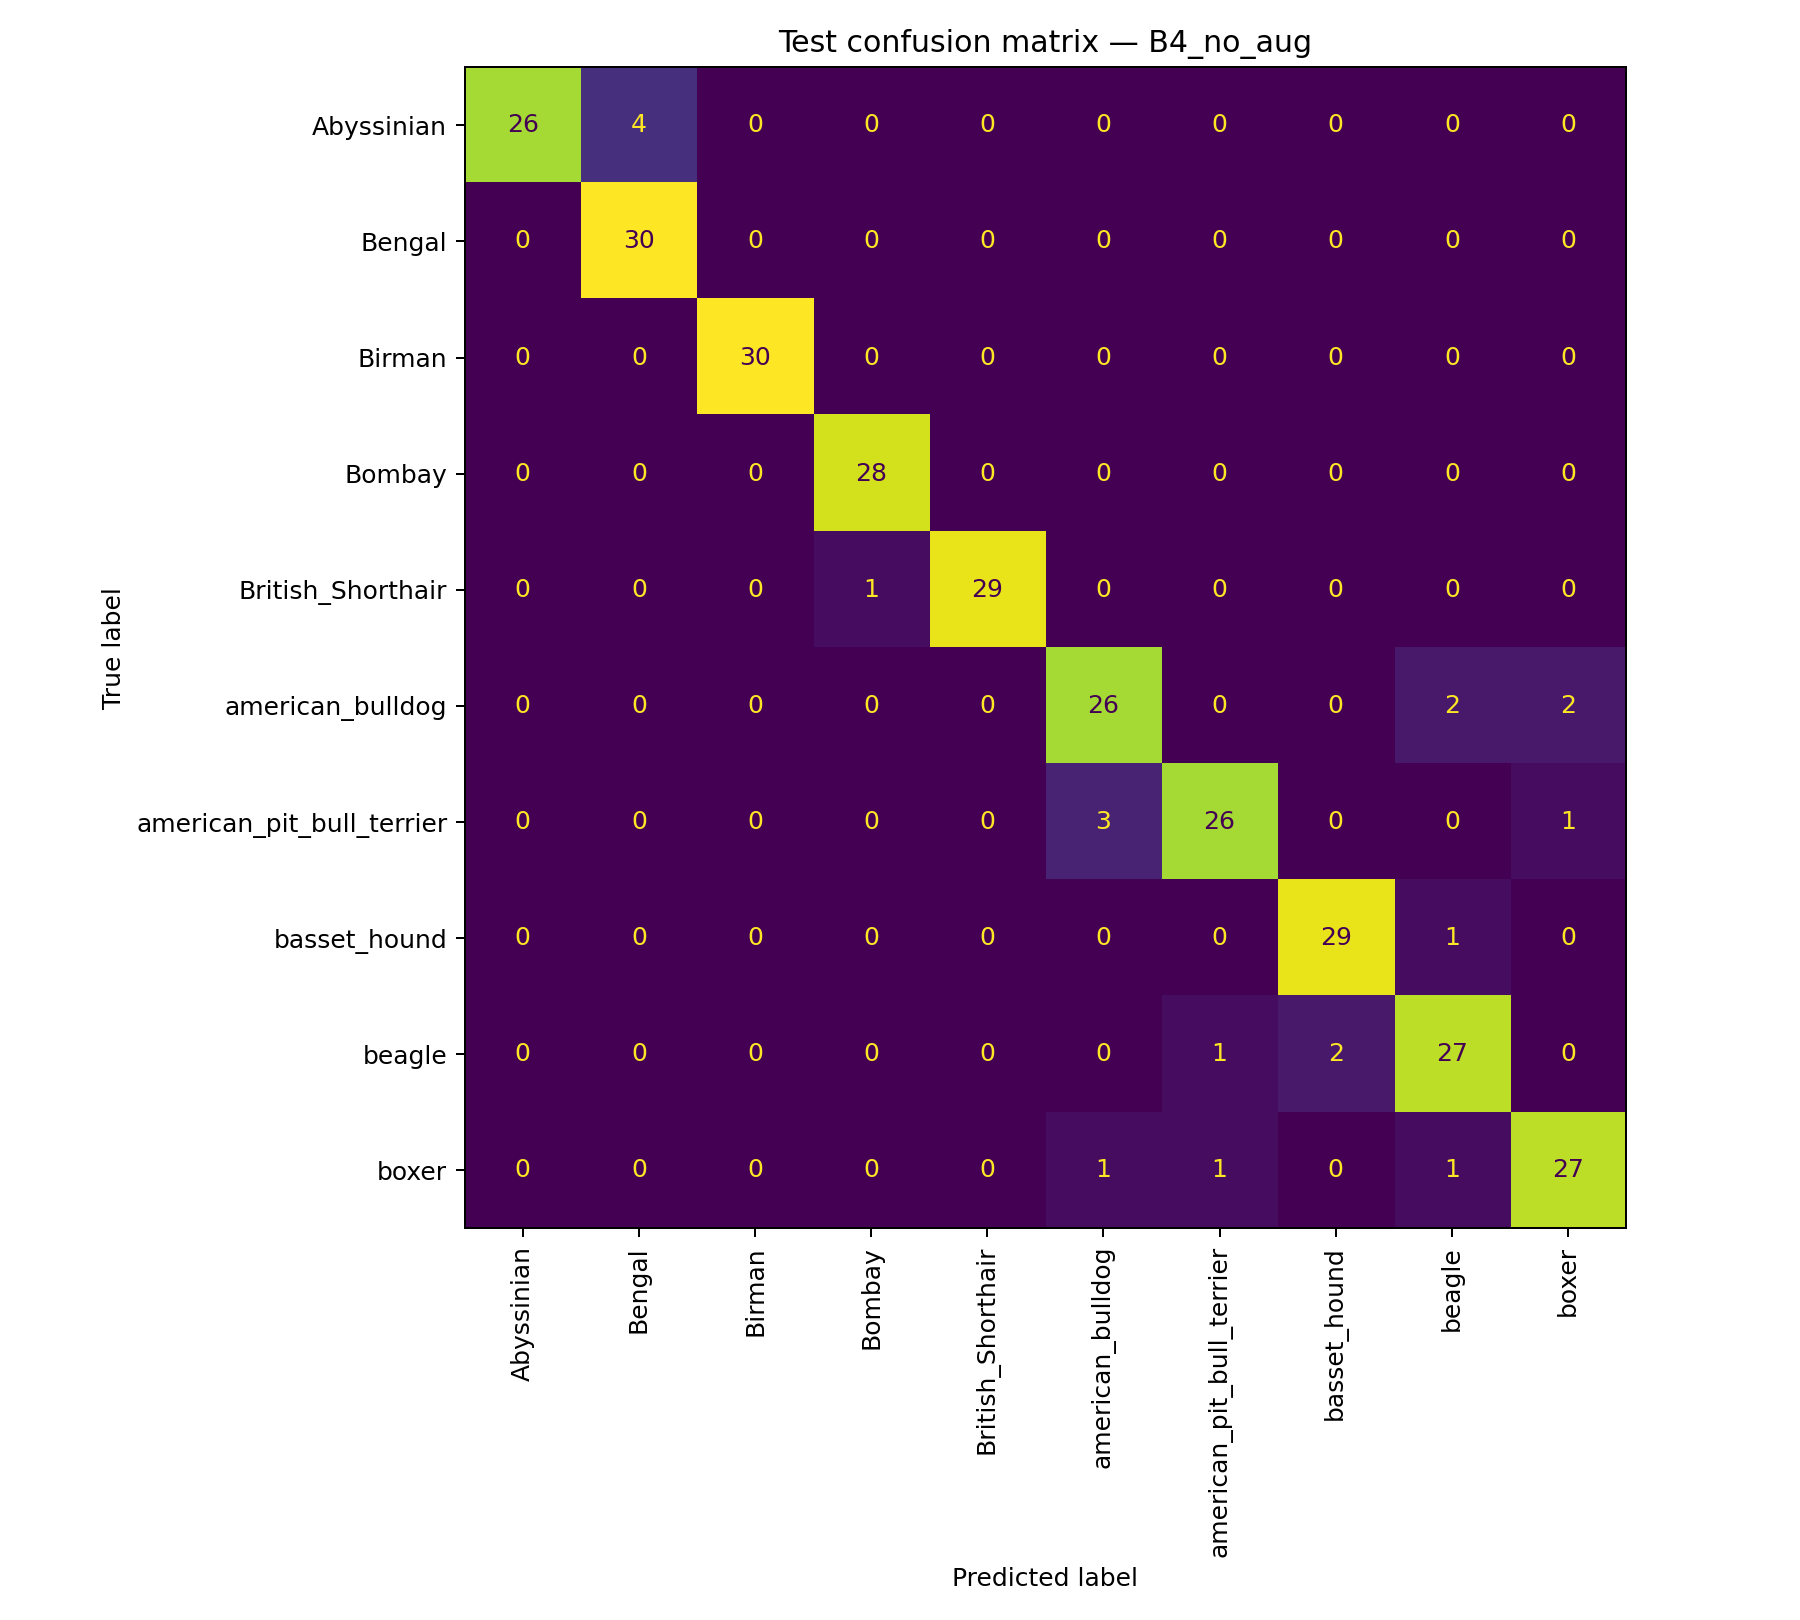

In [4]:
best_name = summary.loc[summary.validation_loss.idxmin(), "name"]
assert best_name == "B4_no_aug"
predictions = pd.read_csv(RAW / best_name / "test_predictions.csv")
matrix = confusion_matrix(predictions.label, predictions.predicted_label, labels=list(range(10)))
assert np.trace(matrix) == 278 and matrix.sum() == 298
print("Model terpilih melalui validation loss:", best_name)
display(pd.DataFrame(matrix, index=protocol["classes"], columns=protocol["classes"]))
display(Image(filename=str(ROOT / "figures/confusion_matrix.png")))


PASS: delta augmentasi cocok dengan CSV asli; satu seed belum membuktikan signifikansi statistik.


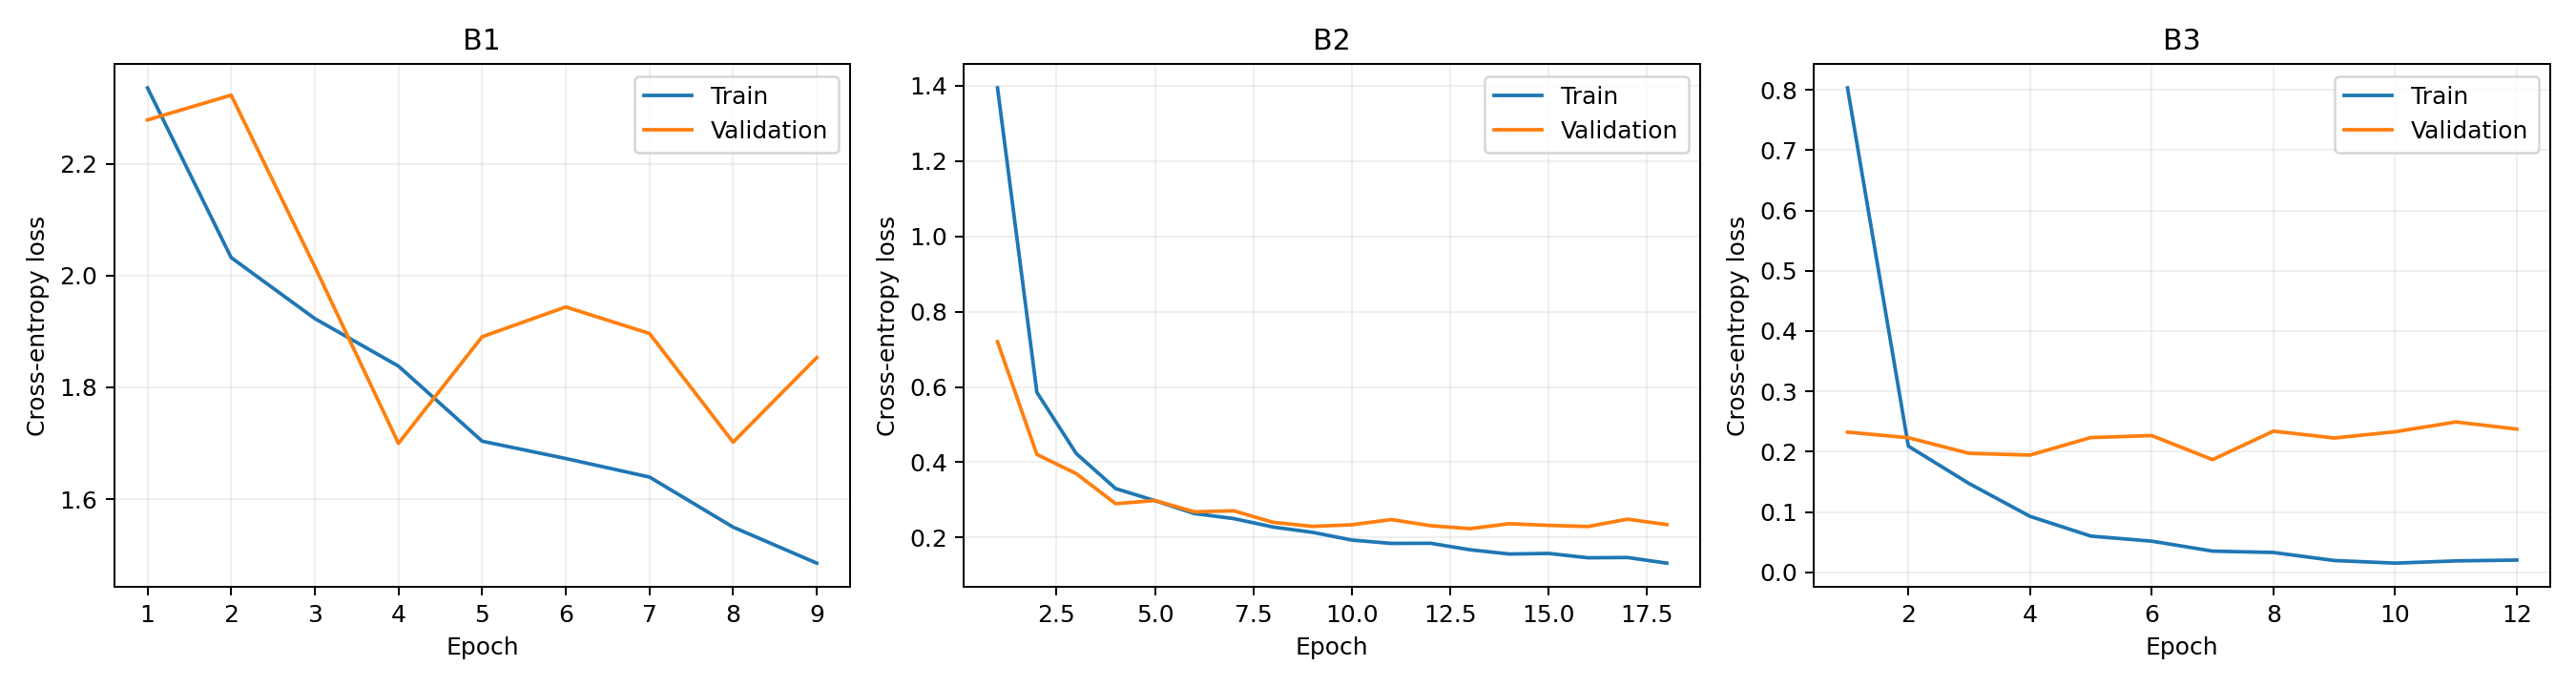

,validation_accuracy,train_eval_accuracy,generalization_gap,test_macro_f1
name,,,,
B3,0.962963,0.993506,0.030544,0.936307
B4_no_aug,0.949495,1.000000,0.050505,0.933086


,B3_minus_B4
validation_accuracy,0.013468
train_eval_accuracy,-0.006494
generalization_gap,-0.019962
test_macro_f1,0.003221


In [5]:
display(Image(filename=str(ROOT / "figures/learning_curves.png")))
control = summary.set_index("name").loc[["B3", "B4_no_aug"],
    ["validation_accuracy", "train_eval_accuracy", "generalization_gap", "test_macro_f1"]]
delta = control.loc["B3"] - control.loc["B4_no_aug"]
saved_delta = pd.read_csv(RAW / "augmentation_delta.csv", index_col=0).iloc[:, 0]
assert np.allclose(delta.to_numpy(), saved_delta.loc[delta.index].to_numpy())
display(control)
display(delta.rename("B3_minus_B4").to_frame())
print("PASS: delta augmentasi cocok dengan CSV asli; satu seed belum membuktikan signifikansi statistik.")


Hipotesis merupakan dugaan dari inspeksi gambar sumber, bukan pembuktian kausal.


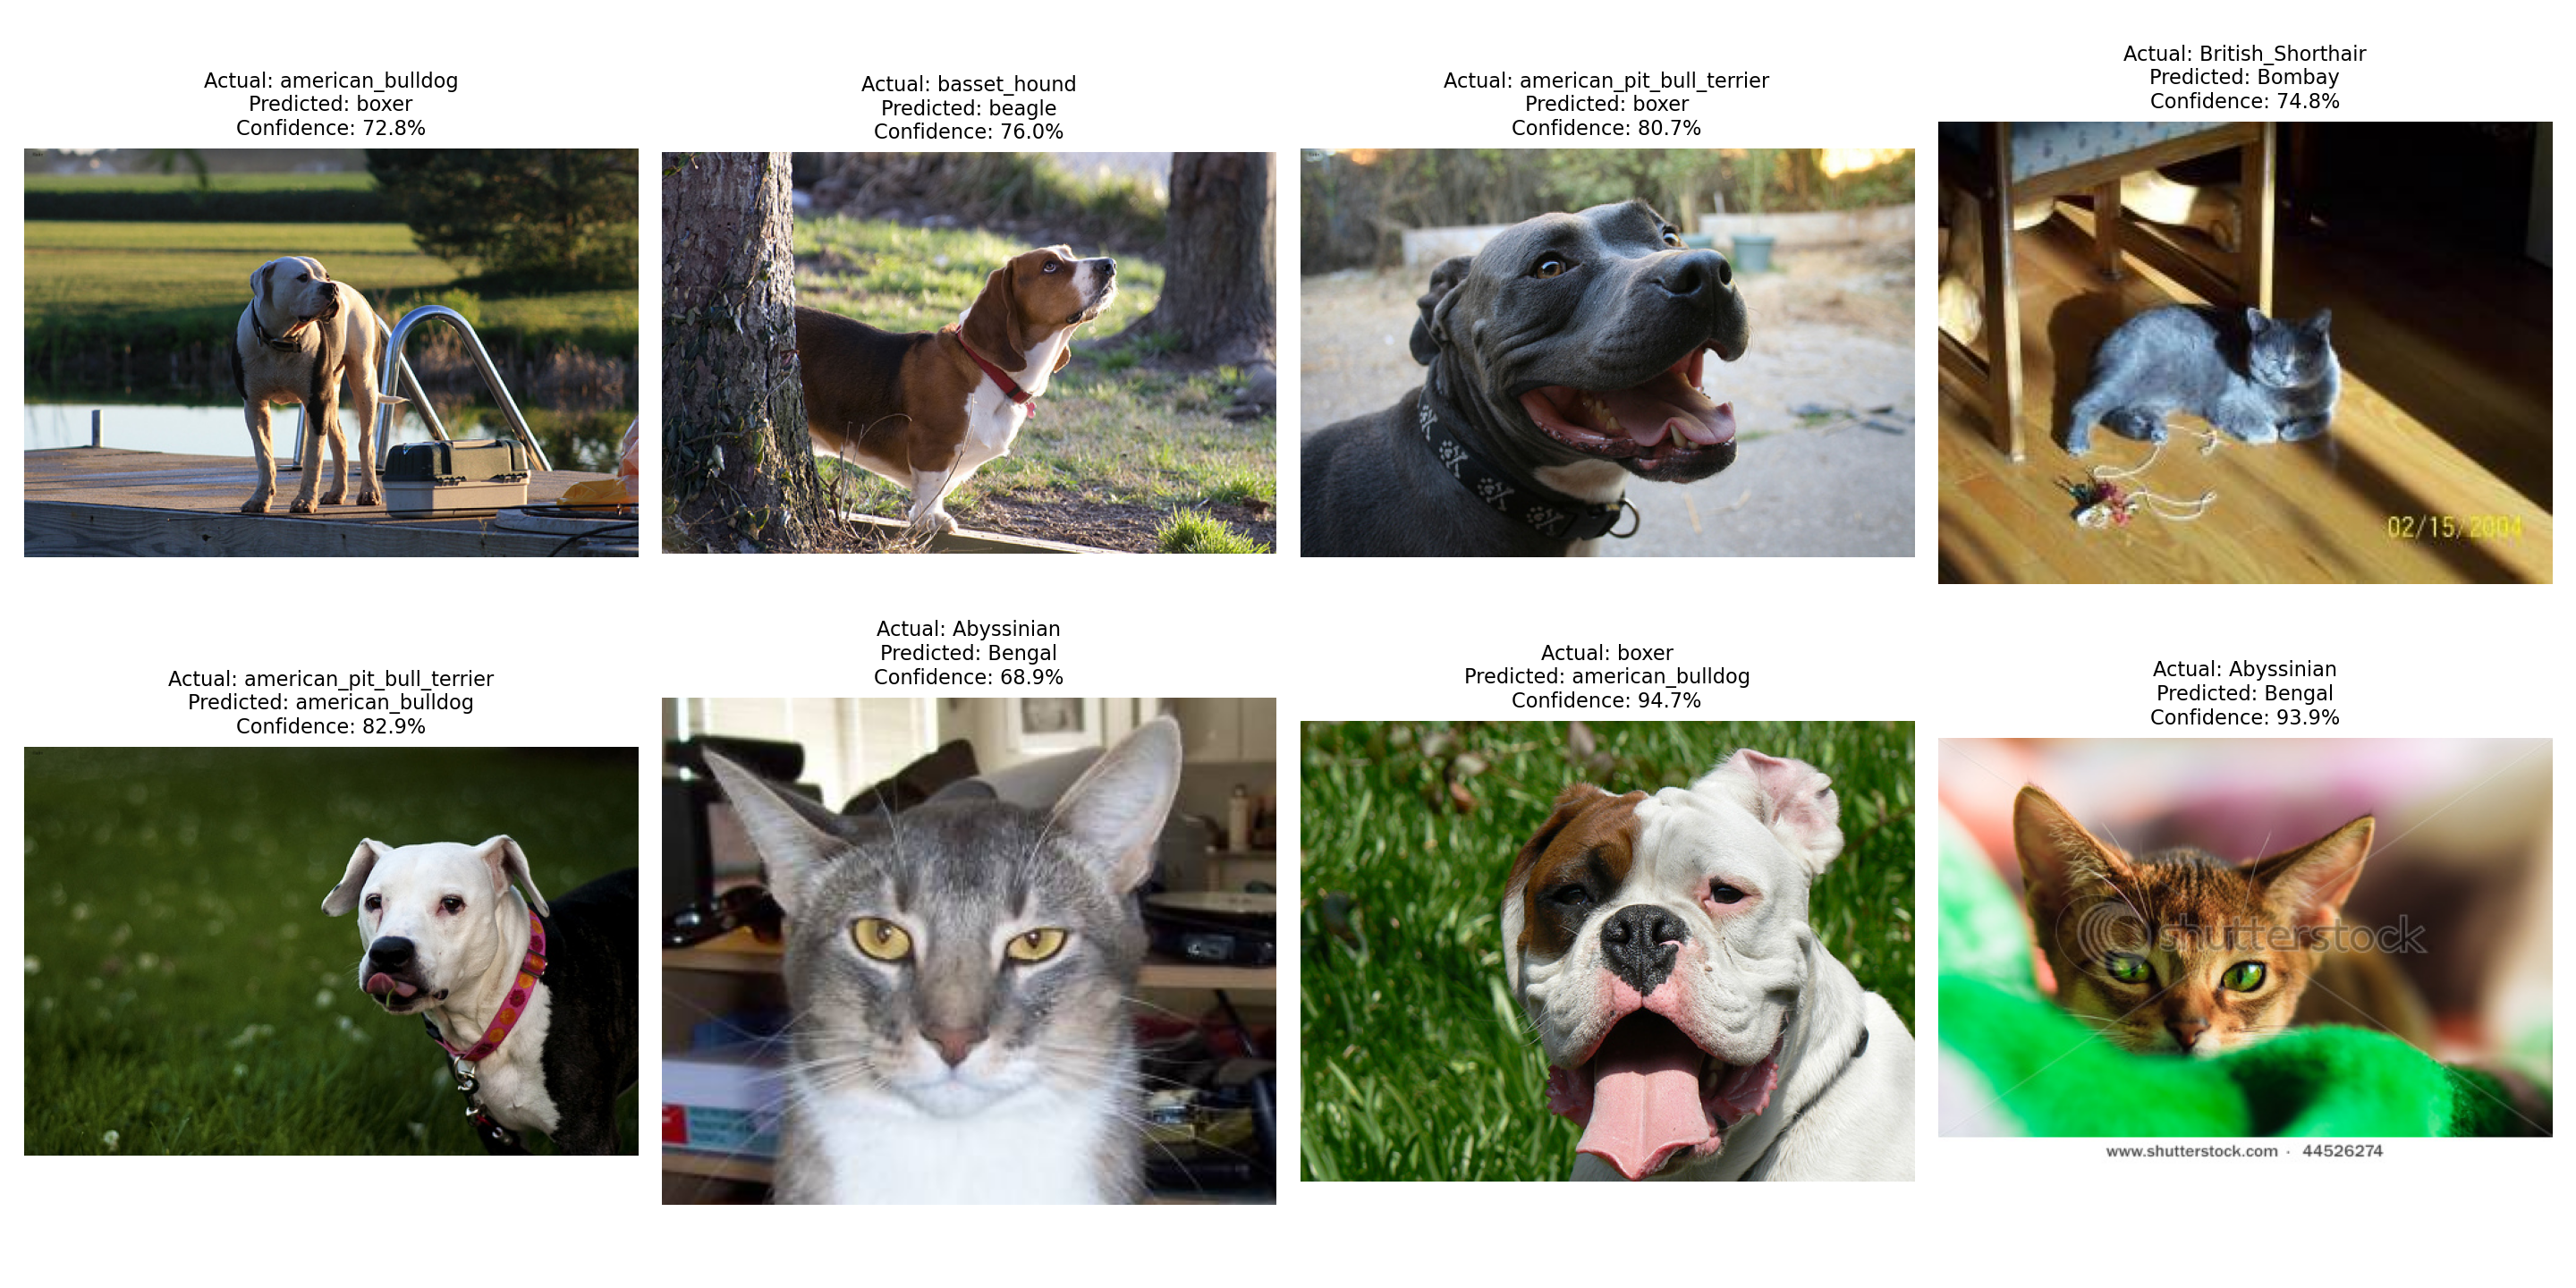

,breed,predicted_breed,confidence,visual_evidence_manual,hypothesis_manual
0,american_bulldog,boxer,0.728189,Hewan relatif kecil; wajah dan tubuh terkena b...,Ukuran subjek dan bayangan mungkin menyamarkan...
1,basset_hound,beagle,0.759589,Tubuh belakang tertutup pohon; bagian kepala l...,Oklusi tubuh mungkin menghilangkan petunjuk pr...
2,american_pit_bull_terrier,boxer,0.806520,Close-up kepala lebar dan moncong; tubuh hampi...,Sudut close-up mungkin membuat bentuk kepala m...
3,British_Shorthair,Bombay,0.748359,Citra kurang tajam; sebagian tubuh dan wajah b...,Bayangan dan ketajaman rendah mungkin mengabur...
4,american_pit_bull_terrier,american_bulldog,0.829437,"Bulu putih, kepala lebar; tubuh hanya tampak s...",Kemiripan warna bulu dan bentuk kepala mungkin...
5,Abyssinian,Bengal,0.688669,Citra kurang tajam; garis gelap tampak pada wa...,Garis wajah dan ketajaman rendah mungkin membu...
6,boxer,american_bulldog,0.947323,"Wajah frontal, moncong pendek dan lebar; tubuh...",Kemiripan moncong pendek dan kepala lebar mung...
7,Abyssinian,Bengal,0.939145,"Pola gelap wajah, watermark; benda hijau menut...",Pola wajah yang menyerupai Bengal mungkin mend...


In [6]:
errors = pd.read_csv(ROOT / "failure_analysis_reviewed.csv")
original = pd.read_csv(RAW / "failure_analysis.csv")
assert len(errors) == len(original) == 8
for column in ["path", "label", "breed", "predicted_label", "predicted_breed"]:
    assert errors[column].tolist() == original[column].tolist()
assert np.allclose(errors.confidence, original.confidence)
assert errors.hypothesis_manual.notna().all()
display(Image(filename=str(ROOT / "figures/failure_samples.png")))
display(errors[["breed", "predicted_breed", "confidence", "visual_evidence_manual", "hypothesis_manual"]])
print("Hipotesis merupakan dugaan dari inspeksi gambar sumber, bukan pembuktian kausal.")


## Integritas bukti
Output di atas berasal dari eksekusi pemeriksaan CSV dan gambar aktual. Tidak ada angka training baru atau output training yang direkonstruksi. Notebook training asli dengan output, identitas GitHub dan verifikasi mandiri mahasiswa tetap merupakan bagian pengumpulan yang harus dilengkapi.